# Exercise 7.4 Fine tune with Lora

### Introduction to LoRA

LoRA (Low-rank adaption) is a machine learning technique that modifies a pretrained model to better suit a specific, often smaller, dataset by adjusting only a small, low-rank subset of the model's parameters. It allows for efficient fine-tuning of large models on task-specific data, reducing the computational costs. 

Suppose we have the weight matrix $\Delta W$ for a given layer. During backpropagation, we learn a $\Delta W$ matrix, which contains information of how much we want to update the original weights to minimize the loss function during training. In regular training and finetuning, the weight update is defined as: 
$$W_{\text{updated}} = W + \Delta W$$

The LoRA methodoffers a more efficient alternative to computing the weight updates $\Delta W$ by learning an approximation of it, $\Delta W \approx AB$. In other words, in LoRA, we have the following, where $A$ and $B$ are two small weight matrices:
$$W_{\text{updated}} = W + AB$$

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/appendix-e_compressed/lora-1.webp" width="500px">

If $x$ is the input data, then we can write the following for regular finetuning:
$$x (W+\Delta W) = x W + x \Delta W$$

Similarly, we can write the following for LoRA:
$$x (W+A B) = x W + x A B$$
The fact that we can keep the LoRA weight matrices separate makes LoRA especially attractive. In practice, this means that we don't have to modify the weights of the pretrained model at all, as we can apply the LoRA matrices on the fly

### Preparing the dataset
Let's prepare the dataset so that we can train the model using LoRA. Most code used are from chapter 6.

In [1]:
import requests
from pathlib import Path
import pandas as pd
import sys
sys.path.append("..")
from src.previous_chapters import *

data_file_path = "sms_spam_collection/SMSSpamCollection.tsv"
df = pd.read_csv(data_file_path, sep="\t", header=None, names=["Label", "Text"])
balanceded_df = create_balanced_dataset(df)
balanceded_df["Label"] = balanceded_df["Label"].map({"ham": 0, "spam": 1})

train_df, val_df, test_df = random_split(balanceded_df, 0.7, 0.1)
train_df.to_csv("train.csv", index=None)
val_df.to_csv("val.csv", index=None)
test_df.to_csv("test.csv", index=None)


In [2]:
import torch
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")
train_dataset = SpamDataset("train.csv", max_length=None, tokenizer=tokenizer)
val_dataset   = SpamDataset("val.csv", max_length=train_dataset.max_length, tokenizer=tokenizer)
test_dataset  = SpamDataset("train.csv", max_length=train_dataset.max_length, tokenizer=tokenizer)

In [3]:
# Create DataLoaders for training, validation and testing
from torch.utils.data import DataLoader

num_workers = 0
batch_size  = 8

torch.manual_seed(123)

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    drop_last=True
)

val_loader = DataLoader(
    dataset=val_dataset,
    batch_size=batch_size,
    num_workers=num_workers,
    drop_last=False
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=batch_size,
    num_workers=num_workers,
    drop_last=False
)

In [4]:
# Verify batches, token size and total number of batches in each dataset
print("Train loader:")
for input_batch, target_batch in train_loader:
    pass
print("Input batch dimensions:", input_batch.shape)
print("Label batch dimensions", target_batch.shape)
print("-"*80)
print(f"{len(train_loader)} training batches")
print(f"{len(val_loader)} validation batches")
print(f"{len(test_loader)} test batches")

Train loader:
Input batch dimensions: torch.Size([8, 120])
Label batch dimensions torch.Size([8])
--------------------------------------------------------------------------------
130 training batches
19 validation batches
131 test batches


### Initialize the model

In [5]:
from ch05.gpt_download import *

CHOOSE_MODEL = "gpt2-small (124M)"
INPUT_PROMPT = "Every effort moves"

BASE_CONFIG  = {
    "vocab_size": 50257,
    "context_length": 1024,
    "drop_rate": 0.0,
    "qkv_bias": True
}

model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

BASE_CONFIG.update(model_configs[CHOOSE_MODEL])

model_size = CHOOSE_MODEL.split(" ")[-1].lstrip("(").rstrip(")")
settings, params = download_and_load_gpt2(model_size=model_size, models_dir="gpt2")

model = GPTModel(BASE_CONFIG)
load_weights_into_gpt(model, params)
model.eval();

File already exists and is up-to-date: gpt2\124M\checkpoint
File already exists and is up-to-date: gpt2\124M\encoder.json
File already exists and is up-to-date: gpt2\124M\hparams.json
File already exists and is up-to-date: gpt2\124M\model.ckpt.data-00000-of-00001
File already exists and is up-to-date: gpt2\124M\model.ckpt.index
File already exists and is up-to-date: gpt2\124M\model.ckpt.meta
File already exists and is up-to-date: gpt2\124M\vocab.bpe


In [6]:
# Make sure the model was loaded correctly
text_1 = "Every effort moves you"

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids(text_1, tokenizer),
    max_new_tokens=15,
    context_size=BASE_CONFIG["context_length"]
)

print(token_ids_to_text(token_ids, tokenizer))

Every effort moves you forward.

The first step is to understand the importance of your work


In [7]:
# Let's prepare the model for classification (similar to chapter 6)
torch.manual_seed(123)
num_classes = 2
model.out_head = torch.nn.Linear(in_features=768, out_features=num_classes)

In [8]:
if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Device: ", device)
model.to(device)

Device:  cuda


GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(1024, 768)
  (drop_emb): Dropout(p=0.0, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=True)
        (W_key): Linear(in_features=768, out_features=768, bias=True)
        (W_value): Linear(in_features=768, out_features=768, bias=True)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_resid): Dropout(p=0.0, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768,

In [9]:
# Calculate inital classification accuracy of non-finetuned model
torch.manual_seed(123)
train_accuracy = calc_accuracy_loader(train_loader, model, device, num_batches=10)
val_accuracy = calc_accuracy_loader(val_loader, model, device, num_batches=10)
test_accuracy = calc_accuracy_loader(test_loader, model, device, num_batches=10)

print(f"Training accuracy: {train_accuracy*100:.2f}%")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

Training accuracy: 46.25%
Validation accuracy: 45.00%
Test accuracy: 47.50%


### Parameter-efficient finetuning with LoRA
Start by initializing a LoRA layer that creates the A & B matrices alonsgside the alpa scaling hyperparamter and the rank (r) hyperparamter.

In [10]:
import math

class LoRALayer(torch.nn.Module):

    def __init__(self, in_dim, out_dim, rank, alpha):
        super().__init__()
        self.A = torch.nn.Parameter(torch.empty(in_dim, rank))
        torch.nn.init.kaiming_uniform_(self.A, a=math.sqrt(5)) # Initialize A matrix
        self.B = torch.nn.Parameter(torch.zeros(rank, out_dim))
        self.alpha = alpha
        self.rank  = rank

    def forward(self, x):
        # Scaling the matrices
        x = (self.alpha / self.rank) * (x @ self.A @self.B)
        return x

- Rank: Hyperparameter that controls the inner dimension of the matrices A and B
- Alpha: Scaling hyperparameter that controls how much influence the low-rank adaption has on the output.

So far, the `LoRALayer` class we implemented above allows us to transform the layer inputs $x$
However, in LoRA, we are usually interested in replacing existing `Linear` layers so that the weight update is applied to the existing pretrained weights, as shown in the figure below

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/appendix-e_compressed/lora-3.webp" width="200px">

In [11]:
class LinearWithLora(torch.nn.Module):
    def __init__(self, linear, rank, alpha):
        super().__init__()
        self.linear = linear
        self.lora   = LoRALayer(
            linear.in_features, linear.out_features, rank, alpha
        )

    def forward(self, x):
        return self.linear(x) + self.lora(x)

In [12]:
def replace_linear_with_lora(model, rank, alpha):
    """Function that replaces standard linear layers with Lora linear layers in our GPT model"""
    for name, module in model.named_children():
        if isinstance(module, torch.nn.Linear):
            setattr(model, name, LinearWithLora(module, rank, alpha))
        else:
            # Recursively apply the function to child modules
            replace_linear_with_lora(module, rank, alpha)

In [13]:
# Freeze the original model parameters and replace them with lora layers
total_params_bef = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters before: {total_params_bef:,}")

for param in model.parameters():
    param.requires_grad = False

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters before: {total_params:,}")

Total trainable parameters before: 124,441,346
Total trainable parameters before: 0


In [14]:
replace_linear_with_lora(model, rank=16, alpha=16)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters before: {total_params:,}")

Total trainable parameters before: 2,666,528


The number of trainable parameters is now almost 50x less when using LoRA.
Lets now double check that the layers have been modified as intended.

In [15]:
model.to(device)
print(model)

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(1024, 768)
  (drop_emb): Dropout(p=0.0, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): LinearWithLora(
          (linear): Linear(in_features=768, out_features=768, bias=True)
          (lora): LoRALayer()
        )
        (W_key): LinearWithLora(
          (linear): Linear(in_features=768, out_features=768, bias=True)
          (lora): LoRALayer()
        )
        (W_value): LinearWithLora(
          (linear): Linear(in_features=768, out_features=768, bias=True)
          (lora): LoRALayer()
        )
        (out_proj): LinearWithLora(
          (linear): Linear(in_features=768, out_features=768, bias=True)
          (lora): LoRALayer()
        )
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): LinearWithLora(
            (linear): Linear(in_features=768, out_featu

In [16]:
# As can be seen the model now contains LinearWithLora layers. 
# Since the B matrix is initialized with 0's the model performance should be unchanged
torch.manual_seed(123)
train_accuracy = calc_accuracy_loader(train_loader, model, device, num_batches=10)
val_accuracy = calc_accuracy_loader(val_loader, model, device, num_batches=10)
test_accuracy = calc_accuracy_loader(test_loader, model, device, num_batches=10)

print(f"Training accuracy: {train_accuracy*100:.2f}%")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

Training accuracy: 46.25%
Validation accuracy: 45.00%
Test accuracy: 47.50%


The same results as before. Now lets finetune the model by reusing the training function from chapter 6

In [17]:
import time

start_time = time.time()
torch.manual_seed(123)

optimizer  = torch.optim.AdamW(model.parameters(), lr=8e-4, weight_decay=0.1)
num_epochs = 5

train_losses, val_losses, train_accs, val_accs, examples_seen = train_classifier_simple(
    model, train_loader, val_loader, optimizer, device, 
    num_epochs=num_epochs, eval_freq=50, eval_iter=5
)

end_time = time.time()
run_time = (end_time - start_time) / 60
print(f"Training completed in {run_time:.2f} minutes")

Ep 1 (Step 000000): Train loss 3.820, Val loss 3.462
Ep 1 (Step 000050): Train loss 0.346, Val loss 0.325
Ep 1 (Step 000100): Train loss 0.063, Val loss 0.144
Training accuracy: 100.00% | Validation accuracy: 92.50%
Ep 2 (Step 000150): Train loss 0.054, Val loss 0.045
Ep 2 (Step 000200): Train loss 0.058, Val loss 0.122
Ep 2 (Step 000250): Train loss 0.041, Val loss 0.199
Training accuracy: 100.00% | Validation accuracy: 95.00%
Ep 3 (Step 000300): Train loss 0.020, Val loss 0.153
Ep 3 (Step 000350): Train loss 0.017, Val loss 0.189
Training accuracy: 100.00% | Validation accuracy: 95.00%
Ep 4 (Step 000400): Train loss 0.018, Val loss 0.094
Ep 4 (Step 000450): Train loss 0.001, Val loss 0.124
Ep 4 (Step 000500): Train loss 0.004, Val loss 0.373
Training accuracy: 100.00% | Validation accuracy: 95.00%
Ep 5 (Step 000550): Train loss 0.025, Val loss 0.236
Ep 5 (Step 000600): Train loss 0.008, Val loss 0.092
Training accuracy: 100.00% | Validation accuracy: 95.00%
Training completed in 1.44

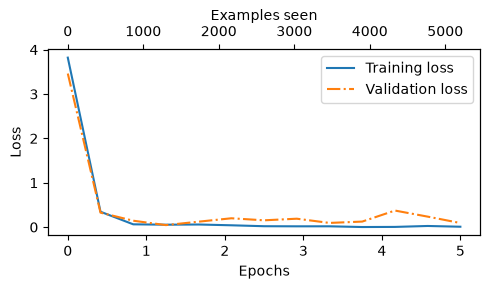

In [18]:
epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
examples_seen_tensor = torch.linspace(0, examples_seen, len(train_losses))

plot_values(epochs_tensor, examples_seen_tensor, train_losses, val_losses, label="loss")

In [21]:
# Calculate accuracy over full dataset
train_accuracy = calc_accuracy_loader(train_loader, model, device)
val_accuracy = calc_accuracy_loader(val_loader, model, device)
test_accuracy = calc_accuracy_loader(test_loader, model, device)

print(f"Training accuracy: {train_accuracy*100:.6f}%")
print(f"Validation accuracy: {val_accuracy*100:.6f}%")
print(f"Test accuracy: {test_accuracy*100:.6f}%")

Training accuracy: 99.903846%
Validation accuracy: 97.986577%
Test accuracy: 99.904306%


As can be seen the model scores extremely high on accuracy beating the model pretrained the normal way:
- Training accuracy: 97.12%
- Validation accuracy: 97.32%
- Test accuracy: 95.67%
Meaning that the LoRA finetuning was successful